# for picking best health_score and terminal models
## based on amount of advantage accumulated and how in-distribution the policy is

In [25]:
import sys
import os
from pathlib import Path
import importlib
import json

import numpy as np
import matplotlib.pyplot as plt
import torch

# Optional but very useful in notebooks
%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import src.rl.evaluate_cql_alpha_sweep as eval_cql
import src.rl.evaluate_terminal_reward_models as etm
import src.rl.action_distribution_sweep as action_dist
import src.rl.clinician_baseline as clin_baseline

# import src.rl.dose_response_shapes as drs

# SAVE_DIR = "/home/jake/Documents/AI_Clinician/models/analysis/cql_alpha_sweep"
# os.makedirs(SAVE_DIR, exist_ok=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# get paths to the models

In [2]:
cohort = "picu"
# health_cohort = "sepsis_picu"
health_cohort = "picu" # dynamic deephit trained on all picu patients, not just sepsis patients

if cohort == "picu":    
    if health_cohort == "picu":
        basic_q_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset"
        print(f"Using basic_q_dir: {basic_q_dir}")
        dynamic_deephit_model_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model"
        print(f"Using dynamic_deephit_model_dir: {dynamic_deephit_model_dir}")
        cql_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset"
        print(f"Using cql_model_dir: {cql_model_dir}")

    elif health_cohort == "sepsis_picu":
        basic_q_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_restricted_dataset"
        print(f"Using basic_q_dir: {basic_q_dir}")
        dynamic_deephit_model_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/sepsis_picu/final_model"
        print(f"Using dynamic_deephit_model_dir: {dynamic_deephit_model_dir}")
        cql_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_restricted_dataset"
        print(f"Using cql_model_dir: {cql_model_dir}")


Using basic_q_dir: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset
Using dynamic_deephit_model_dir: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model
Using cql_model_dir: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset


# get state dim from the dynamic deephit model

In [3]:
# first, load the dynamic deephit hyperparameters so we can get the state dimension
dynamic_deephit_dir = eval_cql.get_model_dirs(dynamic_deephit_model_dir)[0]
print(f"Dynamic DeepHit model directory: {dynamic_deephit_dir}")
# load results.json from dynamic_deephit_dir
with open(os.path.join(dynamic_deephit_dir, "results.json"), "r") as f:
    dynamic_deephit_results = json.load(f)
state_dim = dynamic_deephit_results['hyperparameters']['d_model']
print(f"State dimension from dynamic deephit hyperparameters: {state_dim}")

No choc directories found in /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model
Found model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model/unknown_cx3-20-1_20260821-202508_49e52257
Dynamic DeepHit model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model/unknown_cx3-20-1_20260821-202508_49e52257
State dimension from dynamic deephit hyperparameters: 128


# Load SARSA models x 5 seeds

In [4]:
basic_q_terminal_model_dir = os.path.join(basic_q_dir, "terminal_only")
basic_q_terminal_model_dirs = eval_cql.get_model_dirs(basic_q_terminal_model_dir)

basic_q_terminal_models = []
for model_dir in basic_q_terminal_model_dirs:
    # load terminal sarsa model
    terminal_sarsa_critic, terminal_sarsa_config_manager, terminal_sarsa_hyperparams = etm.load_sarsa_critic(reward_type='terminal', model_dir=model_dir, state_dim=state_dim)
    basic_q_terminal_models.append((terminal_sarsa_critic, terminal_sarsa_config_manager, terminal_sarsa_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163316_with_seeds/unknown_cx3-20-4_20260826-163424_71f56fa6
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163316_with_seeds/unknown_cx3-20-4_20260826-165417_d7c6986a
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163316_with_seeds/unknown_cx3-20-4_20260826-171719_bd2e5ef8
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_fr

In [5]:
basic_q_health_score_model_dir = os.path.join(basic_q_dir, "health_score_change_only")
basic_q_health_score_model_dirs = etm.get_model_dirs(basic_q_health_score_model_dir)

basic_q_health_score_models = []
for model_dir in basic_q_health_score_model_dirs:
    # load health score sarsa model
    health_score_sarsa_critic, health_score_sarsa_config_manager, health_score_sarsa_hyperparams = etm.load_sarsa_critic(reward_type='health_score', model_dir=model_dir, state_dim=state_dim)
    basic_q_health_score_models.append((health_score_sarsa_critic, health_score_sarsa_config_manager, health_score_sarsa_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163652_with_seeds/unknown_cx3-20-4_20260826-172402_1ce5be77
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163652_with_seeds/unknown_cx3-20-4_20260826-165737_72aa451a
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163652_with_seeds/unknown_cx3-20-4_20260826-174709_9876cf65
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-

# Load CQL models

In [6]:
cql_terminal_model_dir = os.path.join(cql_model_dir, "terminal_only", "cql_alpha_sweep")
cql_terminal_model_dirs = eval_cql.get_model_dirs(cql_terminal_model_dir)

cql_terminal_models = []
for model_dir in cql_terminal_model_dirs:
    # load terminal sarsa model
    terminal_actor, terminal_critic, terminal_config_manager, terminal_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_terminal_models.append((terminal_actor, terminal_critic, terminal_config_manager, terminal_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/cql_alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260902_010027/unknown_cx3-20-2_20260902-021721_39aaa0a4
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/cql_alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260902_010027/unknown_cx3-20-2_20260902-014436_e62b101e
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/cql_alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260902_010027/unknown_cx3-20-2_20260902-010146_9fd93408
Found model directory: /home/jake/Documents/AI

In [7]:
cql_health_score_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "cql_alpha_sweep")
cql_health_score_model_dirs = eval_cql.get_model_dirs(cql_health_score_model_dir)

cql_health_score_models = []
for model_dir in cql_health_score_model_dirs:
    # load health score model
    health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_health_score_models.append((health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/cql_alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260902_023647/unknown_cx3-20-2_20260902-034548_22106885
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/cql_alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260902_023647/unknown_cx3-20-2_20260902-060442_08b3dd12
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/cql_alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260902_023647/unknown_cx3-20-2_20260902-030104_fc33f8a9
Found model d

# Load data

In [8]:
health_score_config_manager.data_config['unit_stay_ids_path'] = os.path.join(
    health_score_config_manager.get_data_dir, 'cohorts',
    'icu_units',
    f"{health_score_config_manager.unit.lower()}_stay_ids.csv"
)

health_score_config_manager.data_config['age_stay_ids_path'] = os.path.join(
    health_score_config_manager.get_data_dir, 'cohorts',
    'age', 'pediatric_stay_ids.csv'
)

In [9]:
processors = {}
processors['train'], processors['val'], processors['test'] = etm.load_data(health_score_config_manager, health_score_hyperparams)  

using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type


In [10]:
actions = processors['train'].rl_dataset['actions']

fluids = actions[:, 0]
vasopressors = actions[:, 1] 

# get min non-zero fluid and vasopressor doses
min_nonzero_fluid = fluids[fluids > 0].min()
min_nonzero_vasopressor = vasopressors[vasopressors > 0].min()

print(f"Min non-zero fluid dose: {min_nonzero_fluid}")
print(f"Min non-zero vasopressor dose: {min_nonzero_vasopressor}")

Min non-zero fluid dose: 0.0001319456350756809
Min non-zero vasopressor dose: 0.006044956389814615


# clinician baseline

In [26]:
clinician_baseline_val = clin_baseline.compute_clinician_baseline(processors['val'].rl_dataset["actions"])
clin_baseline.print_clinician_baseline(clinician_baseline_val, label="val")

=== Clinician baseline (val) ===
  fluid: rate=90.9%, mean=0.4958, nonzero_mean=0.5456
  vaso: rate=8.3%, mean=0.0213, nonzero_mean=0.2569


In [27]:
clinician_baseline_test = clin_baseline.compute_clinician_baseline(processors['test'].rl_dataset["actions"])
clin_baseline.print_clinician_baseline(clinician_baseline_test, label="test")

=== Clinician baseline (test) ===
  fluid: rate=90.5%, mean=0.4900, nonzero_mean=0.5415
  vaso: rate=9.4%, mean=0.0260, nonzero_mean=0.2775


# Calculate advantage

## health_score

In [11]:
# Build alpha -> model dicts for each CQL sweep, keyed by each model's own cql_alpha hyperparameter.
# CQL tuples are (actor, critic, config_manager, hyperparams) -> hyperparams at index 3
cql_health_score_by_alpha = {m[3]['cql_alpha']: m for m in cql_health_score_models}
cql_terminal_by_alpha = {m[3]['cql_alpha']: m for m in cql_terminal_models}

print("Health-score alphas found:", sorted(cql_health_score_by_alpha.keys()))
print("Terminal alphas found:", sorted(cql_terminal_by_alpha.keys()))

Health-score alphas found: [0.001, 0.002, 0.003, 0.004, 0.005, 0.006, 0.007, 0.008, 0.009, 0.01]
Terminal alphas found: [0.001, 0.002, 0.003, 0.004, 0.005, 0.006, 0.007, 0.008, 0.009, 0.01]


In [12]:
# Pull val-set severity and training data needed for the occupancy check.
# Adjust these keys if your actual field names differ.
val_health_score = processors['val'].rl_dataset["rewards"]
training_actions = processors['train'].rl_dataset["actions"]
training_health_score = processors['train'].rl_dataset["rewards"]

=== alpha=0.001 ===


    own-critic Q IQR (real clinician actions): 1.0932
    SARSA seed 1 Q IQR (real clinician actions): 0.9660
    SARSA seed 2 Q IQR (real clinician actions): 0.9962
    SARSA seed 3 Q IQR (real clinician actions): 0.9462
    SARSA seed 4 Q IQR (real clinician actions): 1.0221
    SARSA seed 5 Q IQR (real clinician actions): 1.0000
  own-critic advantage:   raw=0.0306, normalized=0.0280
  SARSA-critic advantage: raw mean=0.0762, normalized mean=0.0773 (normalized per-seed=[0.0785 0.0787 0.0785 0.0772 0.0734])
  occupancy support of chosen actions: 89.8%
  done in 6.3s

=== alpha=0.002 ===
    own-critic Q IQR (real clinician actions): 1.3727
    SARSA seed 1 Q IQR (real clinician actions): 0.9660
    SARSA seed 2 Q IQR (real clinician actions): 0.9962
    SARSA seed 3 Q IQR (real clinician actions): 0.9462
    SARSA seed 4 Q IQR (real clinician actions): 1.0221
    SARSA seed 5 Q IQR (real clinician actions): 1.0000
  own-critic advantage:   raw=0.0245, normalized=0.0179
  SARSA-critic

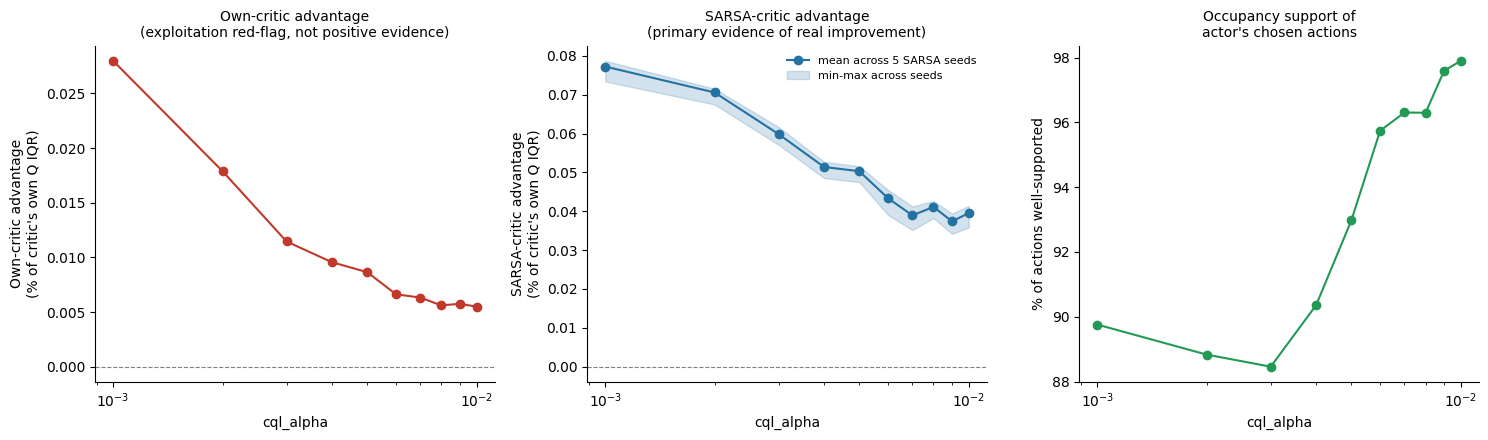

In [13]:
save_path = os.path.join(cql_model_dir, "cql_alpha_sweep_health_score_n_severity_bins_100.png")    


# --- Health-score reward: CQL alpha sweep vs. all 5 health-score SARSA seeds ---
results_health_score, fig_health_score = eval_cql.run_alpha_sweep_analysis(
    cql_health_score_by_alpha,
    processors['val'],
    basic_q_health_score_models,   # the 5 health-score SARSA seeds, as independent judges
    val_health_score,
    training_actions,
    training_health_score,
    n_severity_bins = 100,
    save_path=save_path,
)

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/cql_alpha_sweep_combined_health_score_n_severity_bins_100.png


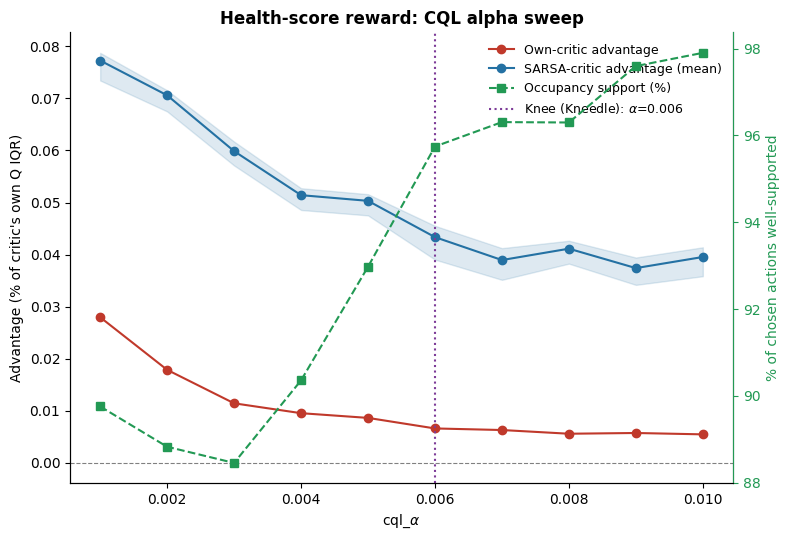

In [14]:
save_path = os.path.join(cql_model_dir, "cql_alpha_sweep_combined_health_score_n_severity_bins_100.png")  

fig = eval_cql.plot_combined_alpha_sweep(
    results_health_score,
    normalized=True,
    title="Health-score reward: CQL alpha sweep",
    save_path=save_path,
)

Ref: Satopaa, V., Albrecht, J., Irwin, D., & Barker, B. (2011). "Finding a 'kneedle' in a haystack: Detecting knee points in system behavior." 31st International Conference on Distributed Computing Systems Workshops.

We selected cql_alpha by identifying the knee of the SARSA-critic
advantage curve as a function of alpha, using the Kneedle
algorithm~\cite{satopaa2011kneedle} (curve="convex", direction="decreasing"),
yielding alpha=0.006. As a corroborating check, we separately identified
the knee of the occupancy-support curve (curve="concave",
direction="increasing", restricted to alpha >= 0.003 to exclude a small,
likely noise-driven non-monotonicity at the lowest tested values), which
independently converged on the same value (alpha=0.006).

In [15]:
knee_advantage = eval_cql.find_knee_alpha(results_health_score, metric="sarsa_advantage", curve="convex", direction="decreasing")
knee_occupancy = eval_cql.find_knee_alpha(
    results_health_score, metric="occupancy", curve="concave", direction="increasing",
    alpha_min=0.003,  # restrict to the genuinely-increasing region, past the early noisy dip
)
print(f"Advantage knee: {knee_advantage}, Occupancy knee: {knee_occupancy}")

Advantage knee: 0.006, Occupancy knee: 0.006


## terminal models

=== alpha=0.001 ===


    own-critic Q IQR (real clinician actions): 3.4613
    SARSA seed 1 Q IQR (real clinician actions): 3.4019
    SARSA seed 2 Q IQR (real clinician actions): 3.4149
    SARSA seed 3 Q IQR (real clinician actions): 3.4782
    SARSA seed 4 Q IQR (real clinician actions): 3.5057
    SARSA seed 5 Q IQR (real clinician actions): 3.5000
  own-critic advantage:   raw=0.2571, normalized=0.0743
  SARSA-critic advantage: raw mean=0.2899, normalized mean=0.0838 (normalized per-seed=[0.0862 0.0946 0.0692 0.0968 0.0723])
  occupancy support of chosen actions: 94.1%
  done in 5.8s

=== alpha=0.002 ===
    own-critic Q IQR (real clinician actions): 3.4598
    SARSA seed 1 Q IQR (real clinician actions): 3.4019
    SARSA seed 2 Q IQR (real clinician actions): 3.4149
    SARSA seed 3 Q IQR (real clinician actions): 3.4782
    SARSA seed 4 Q IQR (real clinician actions): 3.5057
    SARSA seed 5 Q IQR (real clinician actions): 3.5000
  own-critic advantage:   raw=0.2506, normalized=0.0724
  SARSA-critic

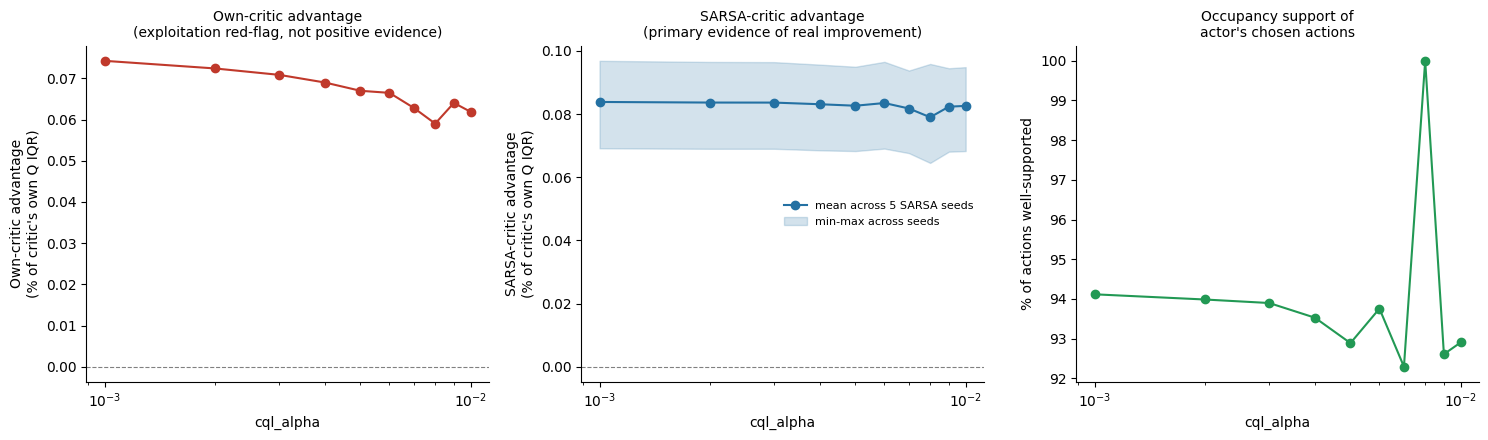

In [16]:
save_path = os.path.join(cql_model_dir, "cql_alpha_sweep_terminal_n_severity_bins_100.png")    


# --- Health-score reward: CQL alpha sweep vs. all 5 health-score SARSA seeds ---
results_terminal, fig_terminal = eval_cql.run_alpha_sweep_analysis(
    cql_terminal_by_alpha,
    processors['val'],
    basic_q_terminal_models,   # the 5 health-score SARSA seeds, as independent judges
    val_health_score,
    training_actions,
    training_health_score,
    n_severity_bins = 100,
    save_path=save_path,
)

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/cql_alpha_sweep_combined_terminal_n_severity_bins_100.png


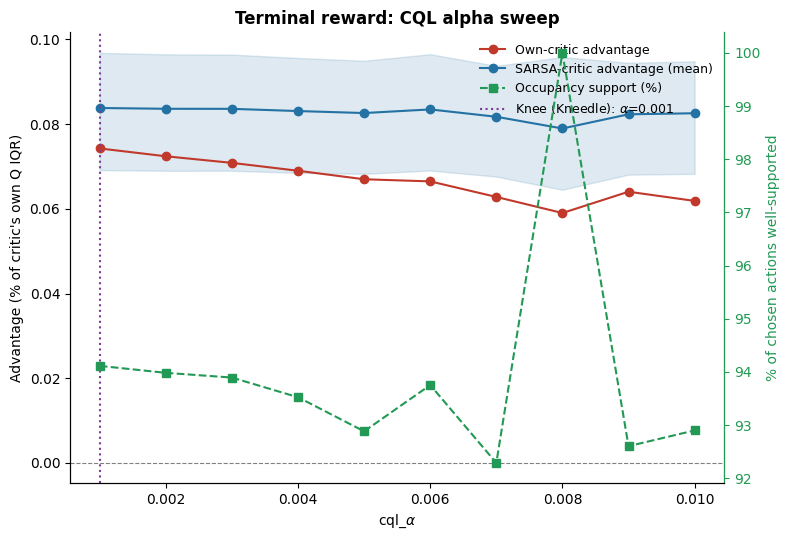

In [17]:
save_path = os.path.join(cql_model_dir, "cql_alpha_sweep_combined_terminal_n_severity_bins_100.png")  

fig = eval_cql.plot_combined_alpha_sweep(
    results_terminal,
    normalized=True,
    title="Terminal reward: CQL alpha sweep",
    save_path=save_path,
)

alpha=0.001: fluid[rate=10.9%, mean=0.1081, nonzero_mean=0.9903]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.002: fluid[rate=12.3%, mean=0.1127, nonzero_mean=0.9183]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.003: fluid[rate=11.4%, mean=0.1139, nonzero_mean=0.9995]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.004: fluid[rate=12.0%, mean=0.1199, nonzero_mean=0.9956]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.005: fluid[rate=13.5%, mean=0.1347, nonzero_mean=0.9957]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.006: fluid[rate=11.8%, mean=0.1178, nonzero_mean=0.9978]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.007: fluid[rate=16.5%, mean=0.1510, nonzero_mean=0.9155]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.008: fluid[rate=0.0%, mean=0.0000, nonzero_mean=nan]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.009: fluid[rate=14.1%, mean=0.1409, nonzero_mean=0.9970]  vaso[rate=0.0%, mean=0.0000, nonze

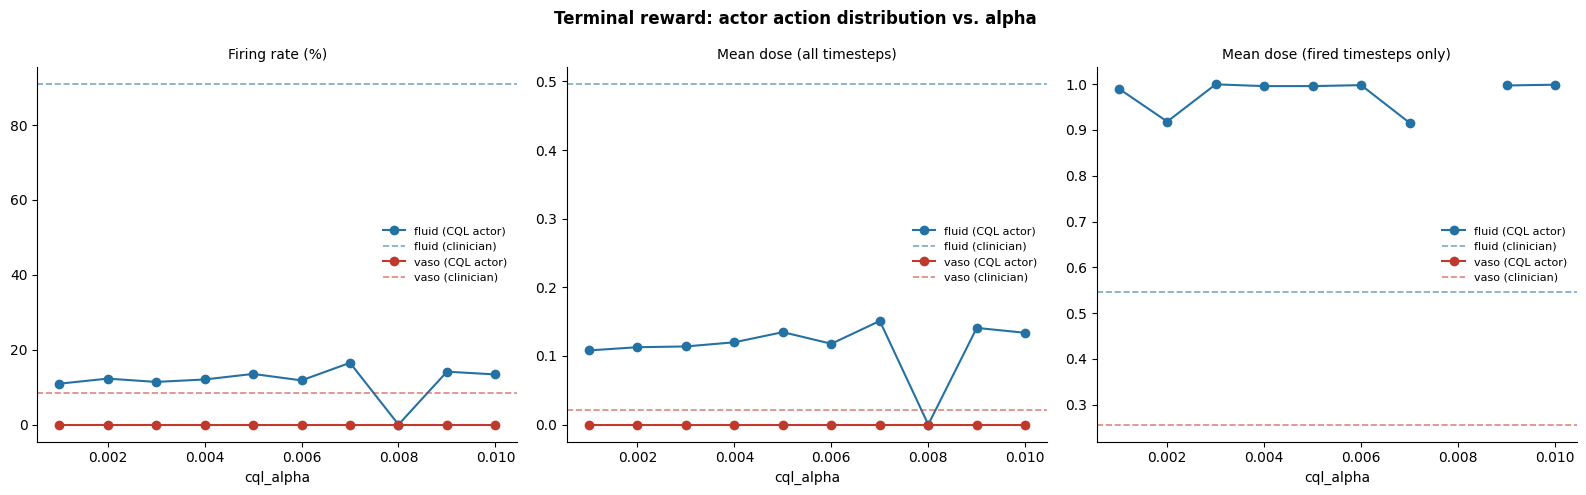

In [31]:
clinician_baseline_val = clin_baseline.compute_clinician_baseline(processors['val'].rl_dataset["actions"])

results_actions_terminal, fig_actions_terminal = action_dist.run_action_distribution_sweep(
    cql_terminal_by_alpha,
    processors['val'],
    clinician_baseline=clinician_baseline_val,
    title="Terminal reward: actor action distribution vs. alpha",
    save_path=os.path.join(cql_model_dir, "cql_alpha_sweep_actions_terminal.png"),
)

alpha=0.001: fluid[rate=30.3%, mean=0.2437, nonzero_mean=0.8053]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.002: fluid[rate=56.3%, mean=0.3414, nonzero_mean=0.6069]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.003: fluid[rate=77.5%, mean=0.4594, nonzero_mean=0.5930]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.004: fluid[rate=87.2%, mean=0.4952, nonzero_mean=0.5676]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.005: fluid[rate=94.8%, mean=0.4810, nonzero_mean=0.5077]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.006: fluid[rate=97.2%, mean=0.4264, nonzero_mean=0.4387]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.007: fluid[rate=97.1%, mean=0.4561, nonzero_mean=0.4698]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.008: fluid[rate=99.1%, mean=0.4676, nonzero_mean=0.4717]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.009: fluid[rate=99.8%, mean=0.4724, nonzero_mean=0.4736]  vaso[rate=0.0%, mean=0.0000, n

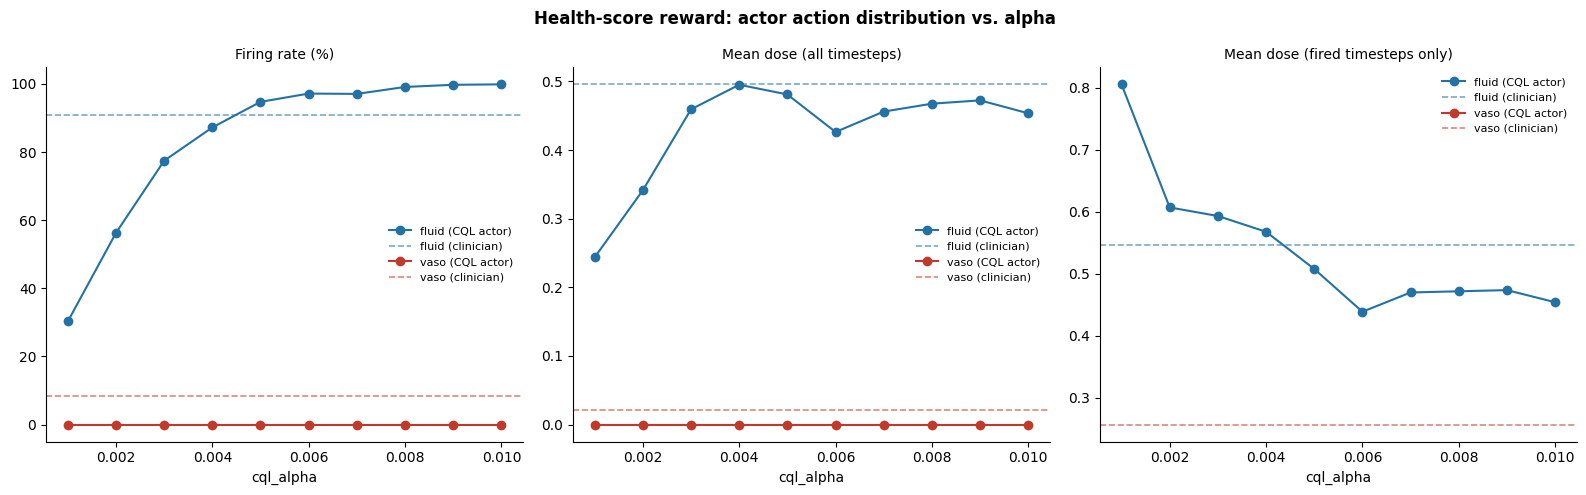

In [32]:
results_actions_health_score, fig_actions_health_score = action_dist.run_action_distribution_sweep(
    cql_health_score_by_alpha,
    processors['val'],
    clinician_baseline=clinician_baseline_val,
    title="Health-score reward: actor action distribution vs. alpha",
    save_path=os.path.join(cql_model_dir, "cql_alpha_sweep_actions_health_score.png"),
)

# final 3 seed models with fixed cql alpha

In [33]:
cql_model_dir

'/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset'

In [34]:
cql_terminal_fixed_alpha_model_dir = os.path.join(cql_model_dir, "terminal_only", "fixed_alpha")
cql_terminal_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_terminal_fixed_alpha_model_dir)

cql_terminal_fixed_alpha_models = []
for model_dir in cql_terminal_fixed_alpha_model_dirs:
    # load terminal sarsa model
    terminal_actor, terminal_critic, terminal_config_manager, terminal_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_terminal_fixed_alpha_models.append((terminal_actor, terminal_critic, terminal_config_manager, terminal_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260906_215328/unknown_cx3-20-6_20260906-220822_0ce993d0
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260906_215328/unknown_cx3-20-6_20260906-223125_f7922617
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260906_215328/unknown_cx3-20-6_20260906-215444_c0ab74de
Found model directory: /home/ja

In [37]:
cql_health_score_fixed_alpha_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "fixed_alpha")
cql_health_score_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_health_score_fixed_alpha_model_dir)

cql_health_score_fixed_alpha_models = []
for model_dir in cql_health_score_fixed_alpha_model_dirs:
    # load health score sarsa model
    health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_health_score_fixed_alpha_models.append((health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260907_095831/unknown_cx3-20-6_20260907-110857_6a599bed
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260907_095831/unknown_cx3-20-6_20260907-095956_924ca060
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260907_095831/unknown_cx3-20-6_20260907-101849_70f2dd3

seed 1/5: fluid[rate=93.2%, mean=0.4356, nonzero_mean=0.4677]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 2/5: fluid[rate=93.3%, mean=0.4161, nonzero_mean=0.4458]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 3/5: fluid[rate=92.5%, mean=0.3793, nonzero_mean=0.4102]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 4/5: fluid[rate=95.4%, mean=0.3856, nonzero_mean=0.4043]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 5/5: fluid[rate=98.7%, mean=0.4178, nonzero_mean=0.4234]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/stage3_actions_health_score.png


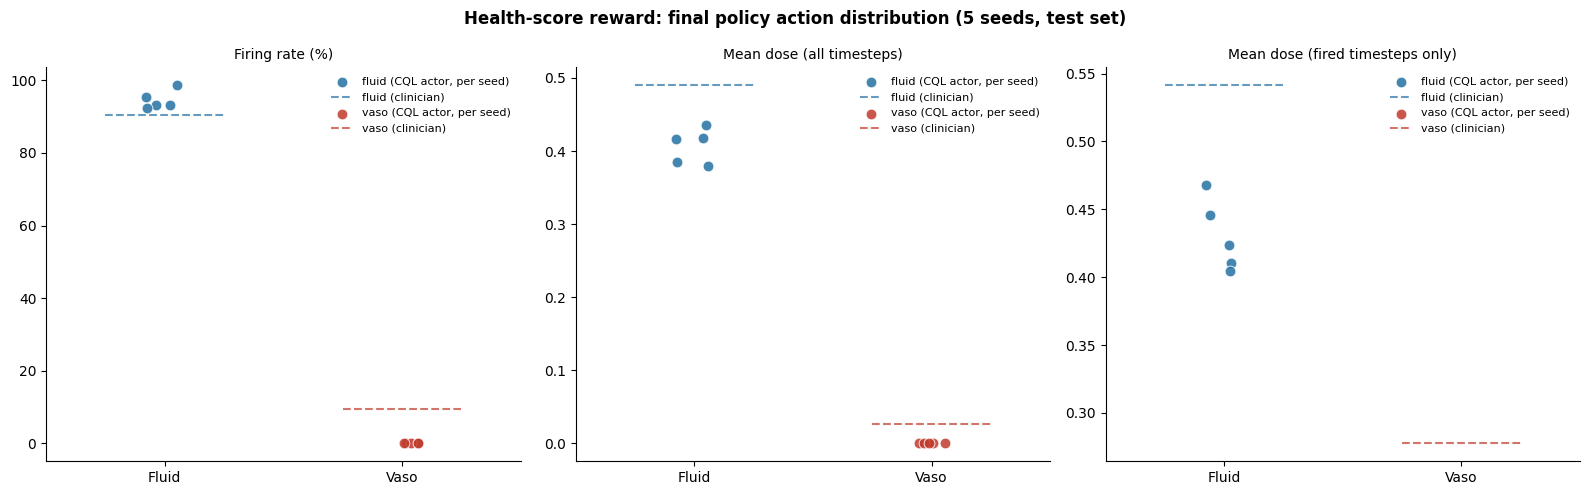

In [38]:
clinician_baseline_test = clin_baseline.compute_clinician_baseline(processors['test'].rl_dataset["actions"])

stats_health_score, fig_health_score = action_dist.run_action_distribution_stage3(
    cql_health_score_fixed_alpha_models,
    processors['test'],
    clinician_baseline=clinician_baseline_test,
    title="Health-score reward: final policy action distribution (5 seeds, test set)",
    save_path=os.path.join(cql_model_dir, "stage3_actions_health_score.png"),
)

seed 1/5: fluid[rate=19.9%, mean=0.1784, nonzero_mean=0.8979]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 2/5: fluid[rate=15.6%, mean=0.1441, nonzero_mean=0.9243]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 3/5: fluid[rate=13.8%, mean=0.1362, nonzero_mean=0.9902]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 4/5: fluid[rate=15.0%, mean=0.1409, nonzero_mean=0.9381]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 5/5: fluid[rate=12.0%, mean=0.1153, nonzero_mean=0.9619]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/stage3_actions_terminal.png


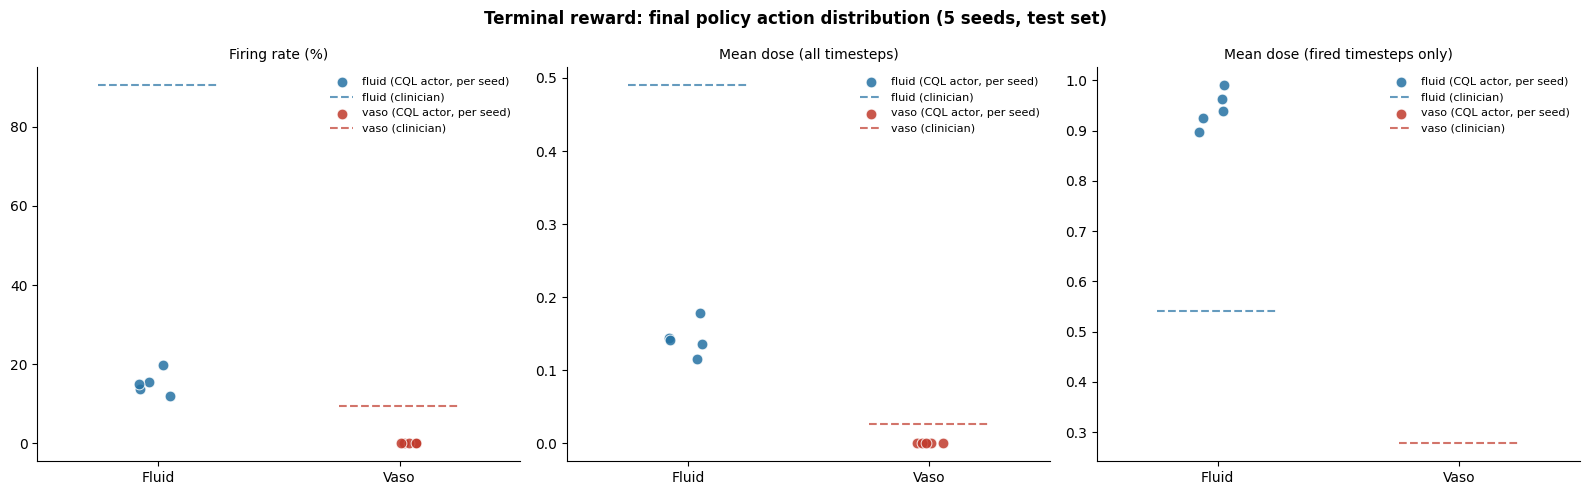

In [39]:
stats_terminal, fig_terminal = action_dist.run_action_distribution_stage3(
    cql_terminal_fixed_alpha_models,
    processors['test'],
    clinician_baseline=clinician_baseline_test,
    title="Terminal reward: final policy action distribution (5 seeds, test set)",
    save_path=os.path.join(cql_model_dir, "stage3_actions_terminal.png"),
)